# Thí nghiệm cấu hình A — Kích thước mạng và batch size của MLP

Thử ba kích thước mạng `(64, 32)`, `(96, 32)`, `(128, 32)` với hai giá trị `batch_size` là 128 và 256. Giữ `alpha=0.001` và `learning_rate_init=0.001` như bộ thắng V2. Dùng cùng dữ liệu `data/processed` và cùng pipeline mã hóa cột lịch, chuẩn hóa mục tiêu.

Ở mỗi mức batch size, so MAE để xem thay đổi kích thước mạng ảnh hưởng ra sao. Lưới có cả bộ V2 `(64, 32), 256` và bộ V3 `(128, 32), 128`. Mốc validation của V2 là **232,022 xe/giờ**.

**Nguồn dữ liệu chung (19/11/2026):** Code đọc dữ liệu đã chuyển sang `src.experiment_data.load_experiment_splits`. `processed` dùng snapshot bàn giao; `raw` dùng cho CV trước điền thiếu; `filled` giữ schema nhãn và học điền từ train. Các output/metrics đang hiển thị là kết quả lịch sử, chưa chạy lại sau thay đổi này.


## Params

In [1]:
MODEL_PARAMS = {
    "MLP": {
        "hidden_layer_sizes": (64, 32),
        "activation": "relu",
        "solver": "adam",
        "alpha": 0.001,
        "learning_rate_init": 0.001,
        "batch_size": 256,
        "max_iter": 500,
        "early_stopping": False,
        "random_state": 42,
    },
}

PARAM_GRID = {
    "model__regressor__batch_size": [128, 256],
    "model__regressor__hidden_layer_sizes": [(64, 32), (96, 32), (128, 32)],
}
CV_SPLITS = 3
V2_VALIDATION_MAE = 232.0224559721174

CALENDAR_COLUMNS = ["hour", "day_of_week", "month"]
BINARY_COLUMNS = ["is_weekend", "is_holiday"]
TARGET_COLUMN = "traffic_volume"
CLIP_NEGATIVE_PREDICTIONS = True
HOURS_TO_PLOT = 72

## Đọc dữ liệu và chọn đặc trưng cấu hình A

In [2]:
from datetime import datetime
from pathlib import Path

import pandas as pd
from IPython.display import display
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

cwd = Path.cwd()
project_dir = next(
    (
        candidate
        for parent in (cwd, *cwd.parents)
        for candidate in (parent, parent / "metro_interstate_traffic_volume")
        if (candidate / "data" / "processed" / "train.csv").is_file()
    ),
    None,
)
if project_dir is None:
    raise FileNotFoundError("Không tìm thấy data/processed/train.csv.")

processed_dir = project_dir / "data" / "processed"
import sys
if str(project_dir) not in sys.path:
    sys.path.insert(0, str(project_dir))
from src.experiment_data import load_experiment_splits

data_splits = load_experiment_splits(project_dir=project_dir)
train, validation = data_splits["train"], data_splits["validation"]

assert train.columns.equals(validation.columns)
for part in (train, validation):
    assert part["date_time"].is_unique
    assert part["date_time"].is_monotonic_increasing
assert train["date_time"].max() < validation["date_time"].min()

holiday_columns = [column for column in train.columns if column.startswith("holiday_")]
binary_columns = BINARY_COLUMNS + holiday_columns
features_A = CALENDAR_COLUMNS + binary_columns

for part in (train, validation):
    assert part[features_A + [TARGET_COLUMN]].notna().all().all()

X_train, y_train = train[features_A], train[TARGET_COLUMN]
X_validation, y_validation = validation[features_A], validation[TARGET_COLUMN]

## Chạy Grid CV trên tập train

Mỗi fold học từ các giờ đứng trước phần chấm. Grid CV thực hiện 18 lần fit, rồi fit lại bộ có MAE thấp nhất trên toàn bộ tập train. MAE trong CV và validation đều áp dụng cùng quy tắc chặn dự đoán âm.

In [3]:
preprocessor = ColumnTransformer([
    (
        "calendar",
        OneHotEncoder(handle_unknown="ignore", sparse_output=False),
        CALENDAR_COLUMNS,
    ),
    ("binary", "passthrough", binary_columns),
])

# Chuẩn hóa mục tiêu từ train và đổi dự đoán về đơn vị xe/giờ.
pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("model", TransformedTargetRegressor(
        regressor=MLPRegressor(**MODEL_PARAMS["MLP"]),
        transformer=StandardScaler(),
    )),
])
def predict_volume(estimator, X):
    prediction = estimator.predict(X)
    if CLIP_NEGATIVE_PREDICTIONS:
        prediction = prediction.clip(min=0)
    return prediction


def negative_mae(estimator, X, y):
    return -mean_absolute_error(y, predict_volume(estimator, X))


search = GridSearchCV(
    estimator=pipeline,
    param_grid=PARAM_GRID,
    scoring=negative_mae,
    cv=TimeSeriesSplit(n_splits=CV_SPLITS),
    refit=True,
    error_score="raise",
    verbose=1,
)
search.fit(X_train, y_train)
model = search.best_estimator_

cv_results = search.cv_results_
cv_table = pd.DataFrame(cv_results["params"]).rename(
    columns=lambda name: name.removeprefix("model__regressor__"),
)
for fold in range(CV_SPLITS):
    cv_table[f"MAE fold {fold + 1}"] = -cv_results[f"split{fold}_test_score"]
cv_table["MAE CV"] = -cv_results["mean_test_score"]
cv_table["Độ lệch chuẩn MAE"] = cv_results["std_test_score"]
cv_table["Hạng"] = cv_results["rank_test_score"]
cv_table["Bộ V2"] = (
    cv_table["hidden_layer_sizes"].map(lambda layers: layers == (64, 32))
    & cv_table["batch_size"].eq(256)
)
cv_table["Bộ V3"] = (
    cv_table["hidden_layer_sizes"].map(lambda layers: layers == (128, 32))
    & cv_table["batch_size"].eq(128)
)
cv_table["Được chọn"] = cv_table.index == search.best_index_
cv_table = cv_table.sort_values("Hạng", kind="stable").reset_index(drop=True)
display(cv_table.round({"MAE CV": 3, "Độ lệch chuẩn MAE": 3}))

architecture_table = cv_table.pivot(
    index="hidden_layer_sizes", columns="batch_size", values="MAE CV",
).sort_index()
display(architecture_table.round(3))

Fitting 3 folds for each of 6 candidates, totalling 18 fits


,batch_size,hidden_layer_sizes,MAE fold 1,MAE fold 2,MAE fold 3,MAE CV,Độ lệch chuẩn MAE,Hạng,Bộ V2,Bộ V3,Được chọn
0,256,"(64, 32)",275.428653,274.059658,316.059519,288.516,19.484,1,True,False,True
1,128,"(96, 32)",277.704609,275.397356,312.544713,288.549,16.994,2,False,False,False
2,256,"(96, 32)",272.031958,280.124178,317.037469,289.731,19.589,3,False,False,False
3,128,"(64, 32)",280.930128,282.202767,313.988411,292.374,15.293,4,False,False,False
4,256,"(128, 32)",272.459364,276.647160,328.045173,292.384,25.274,5,False,False,False
5,128,"(128, 32)",273.717140,275.622287,332.211196,293.850,27.136,6,False,True,False


batch_size,128,256
hidden_layer_sizes,,
"(64, 32)",292.374,288.516
"(96, 32)",288.549,289.731
"(128, 32)",293.850,292.384


## Đánh giá trên validation và lưu Excel

File Excel của mỗi lần chạy có hai sheet. **Kết quả** ghi điểm validation và tham số của bộ được chọn. **Grid CV** ghi điểm từng fold của cả sáu tổ hợp. Cột chênh lệch MAE âm nghĩa là bộ được chọn cải thiện so với kết quả V2 đã lưu.

In [4]:
prediction_table = validation[["date_time", TARGET_COLUMN]].copy()
prediction = predict_volume(model, X_validation)
prediction_table["MLP"] = prediction

results = pd.DataFrame([{
    "Mô hình": "MLP",
    "MAE": mean_absolute_error(y_validation, prediction),
    "RMSE": mean_squared_error(y_validation, prediction) ** 0.5,
    "R2": r2_score(y_validation, prediction),
    "MAE CV": -search.best_score_,
    "MAE validation V2": V2_VALIDATION_MAE,
    "Chênh lệch MAE so với V2": mean_absolute_error(y_validation, prediction) - V2_VALIDATION_MAE,
}])
display(results.round({"MAE": 3, "RMSE": 3, "R2": 4}))

run_time = datetime.now().astimezone()
run_id = run_time.strftime("%Y%m%d_%H%M%S_%f")
experiment_dir = project_dir / "experiments" / "17-11-2026_ConfigA_ModelLMP_Phuc"
excel_path = experiment_dir / f"ConfigA_MLP_V4_{run_id}.xlsx"

fitted_mlp = model.named_steps["model"].regressor_
fitted_params = fitted_mlp.get_params()
run_details = {
    "run_id": run_id,
    "thời gian": run_time.isoformat(timespec="seconds"),
    "cấu hình": "A",
    "số mẫu train": len(y_train),
    "số mẫu validation": len(y_validation),
    "giới hạn dự đoán âm": CLIP_NEGATIVE_PREDICTIONS,
}
params_row = {name: fitted_params[name] for name in MODEL_PARAMS["MLP"]}
params_row["hidden_layer_sizes"] = str(params_row["hidden_layer_sizes"])
export = results.assign(**run_details, **params_row, n_iter=fitted_mlp.n_iter_)
with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
    export.to_excel(writer, sheet_name="Kết quả", index=False)
    cv_export = cv_table.assign(hidden_layer_sizes=cv_table["hidden_layer_sizes"].map(str))
    cv_export.to_excel(writer, sheet_name="Grid CV", index=False)
print(f"Đã lưu Excel tại {excel_path}")

,Mô hình,MAE,RMSE,R2,MAE CV,MAE validation V2,Chênh lệch MAE so với V2
0,MLP,232.022,359.827,0.9665,288.515943,232.022456,2.842171e-14


Đã lưu Excel tại d:\SGU_HocMay_2026-2027\metro_interstate_traffic_volume\experiments\17-11-2026_ConfigA_ModelLMP_Phuc\ConfigA_MLP_V4_20261117_233306_014915.xlsx


## Vẽ và lưu biểu đồ dự đoán

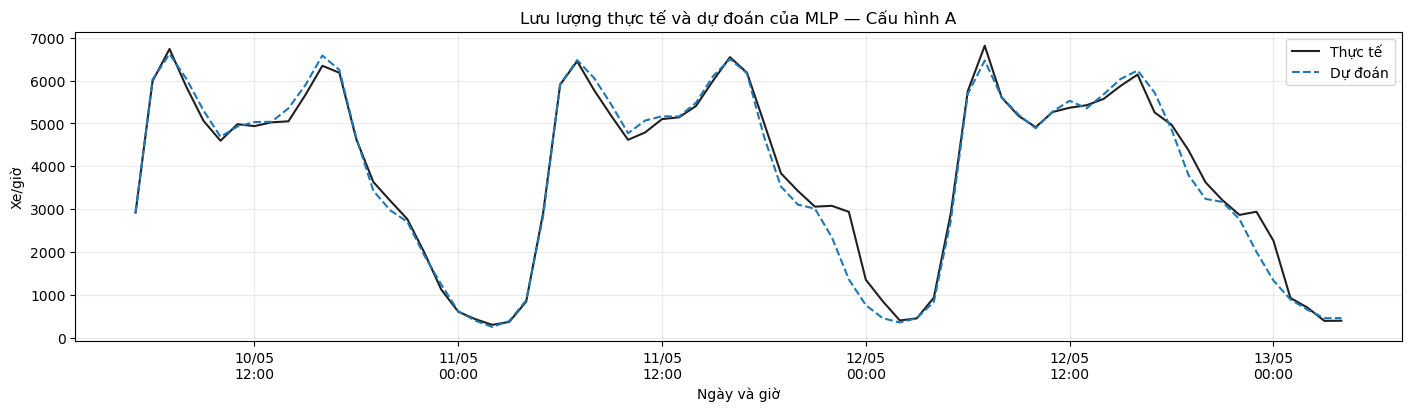

In [5]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt

plot_index = pd.date_range(
    start=prediction_table["date_time"].min(),
    periods=HOURS_TO_PLOT,
    freq="h",
)
# Giữ NaN ở các giờ thiếu để biểu đồ ngắt tại khoảng trống.
plot_data = prediction_table.set_index("date_time").reindex(plot_index)

fig, ax = plt.subplots(figsize=(14, 4), layout="constrained")
ax.plot(plot_data.index, plot_data[TARGET_COLUMN], color="#202020", label="Thực tế")
ax.plot(plot_data.index, plot_data["MLP"], linestyle="--", label="Dự đoán")
ax.set_title("Lưu lượng thực tế và dự đoán của MLP — Cấu hình A")
ax.set_ylabel("Xe/giờ")
ax.grid(alpha=0.25)
ax.legend(loc="upper right")
ax.xaxis.set_major_locator(mdates.HourLocator(byhour=[0, 12]))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m\n%H:%M"))
ax.set_xlabel("Ngày và giờ")

output_dir = experiment_dir / "img"
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"config_a_mlp_v4_{HOURS_TO_PLOT}h_{run_id}.png"
fig.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()